# Step 15 — Bonus features

This notebook tests the four bonus features against the same `include/` modules the DAGs use:

1. **Slack alert on failure:** `alerts.notify_failure` as every task's `on_failure_callback`, reading the `SLACK_WEBHOOK_URL` Airflow Variable.
2. **Store-capacity check:** daily orders per store vs `capacity_orders_per_day`, recorded in `dq_results` by both pipelines.
3. **Quality trend chart:** built from the `dq_results` history.
4. **SCD Type 2 loyalty-tier history:** `etl_dim_customer_history` (pandas) and `dim_customer_history` (SQL).

Every scenario runs on a temporary copy of the source files; the original CSVs are never changed. Run from the repository root.

In [1]:
# Use the same modules as the Airflow DAGs; all scenario output goes to a temp folder.
from pathlib import Path
import os, sys, json, shutil, tempfile, threading
from datetime import datetime
from http.server import BaseHTTPRequestHandler, HTTPServer

REPO_ROOT = Path.cwd() if (Path.cwd() / 'include').exists() else Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT / 'include'))

import duckdb
import pandas as pd
import nammamart_etl as etl
import nammamart_elt as elt
from alerts import format_failure_message, notify_failure, notify_quality_warning
from dq_trend import load_dq_trend, plot_dq_trend

WORK = Path(tempfile.mkdtemp(prefix='nammamart_step15_'))

def source_copy(name):
    target = WORK / name
    shutil.copytree(etl.DATA_DIR, target)
    return target

print('Repository:', REPO_ROOT)

Repository: /Users/kumarsamanvaya/Documents/IITR - FDE Course/Data Pipepline Assignment/_Samy_IIT_Roorkie_CEC_Futurenece_Data_Pipeline_to_ML_Model


## 1. Slack alert on failure

A local HTTP server stands in for the Slack webhook so the exact payload can be inspected. In Airflow the URL comes from the `SLACK_WEBHOOK_URL` Variable; outside Airflow `send_slack_alert` falls back to the environment variable of the same name.

In [2]:
# Capture what the callback would post to Slack.
captured = []

class FakeSlack(BaseHTTPRequestHandler):
    def do_POST(self):
        captured.append(json.loads(self.rfile.read(int(self.headers['Content-Length']))))
        self.send_response(200); self.end_headers(); self.wfile.write(b'ok')
    def log_message(self, *args):
        pass

server = HTTPServer(('127.0.0.1', 0), FakeSlack)
threading.Thread(target=server.serve_forever, daemon=True).start()
os.environ['SLACK_WEBHOOK_URL'] = f'http://127.0.0.1:{server.server_port}/fake-webhook'

class FakeTaskInstance:
    dag_id = 'nammamart_etl_samy'
    task_id = 'extract_products'
    try_number = 3

context = {
    'ti': FakeTaskInstance(),
    'run_id': 'scheduled__2026-10-23T03:30:00+00:00',
    'exception': FileNotFoundError("[Errno 2] No such file or directory: 'include/data/nammamart/products.csv'"),
}
notify_failure(context)
notify_quality_warning('nammamart_elt_samy', 'scheduled__2026-10-23T03:30:00+00:00',
                       ['orders.csv:order_id:Order volume dropped more than 90% vs previous run'])
server.shutdown()
del os.environ['SLACK_WEBHOOK_URL']

assert len(captured) == 2 and 'extract_products' in captured[0]['text']
for message in captured:
    print(message['text'], end='\n\n')

[Slack] Alert sent successfully. HTTP 200
[Slack] Alert sent successfully. HTTP 200


:red_circle: *NammaMart pipeline failure*
*DAG:* nammamart_etl_samy
*Task:* extract_products (attempt 3, retries exhausted)
*Run:* scheduled__2026-10-23T03:30:00+00:00
*Error:* [Errno 2] No such file or directory: 'include/data/nammamart/products.csv'
The 9:00 AM report is not ready; fix the cause and Clear the failed task.

:warning: *NammaMart data-quality warning* (nammamart_elt_samy, run scheduled__2026-10-23T03:30:00+00:00)
• orders.csv:order_id:Order volume dropped more than 90% vs previous run
The run completed; check dq_results before using today's numbers.



In [3]:
# Without a webhook configured the alert is printed to the task log instead,
# so a missing Variable never hides a failure.
notify_failure(context)

[Slack] No SLACK_WEBHOOK_URL set. Printing alert to console instead:
:red_circle: *NammaMart pipeline failure*
*DAG:* nammamart_etl_samy
*Task:* extract_products (attempt 3, retries exhausted)
*Run:* scheduled__2026-10-23T03:30:00+00:00
*Error:* [Errno 2] No such file or directory: 'include/data/nammamart/products.csv'
The 9:00 AM report is not ready; fix the cause and Clear the failed task.


## 2. Store-capacity check

Orders per store per day are compared with `capacity_orders_per_day`. Stores whose capacity is itself invalid (S12 = 0) are excluded, because *Store capacity is not positive* already flags them.

In [4]:
# Real data: how close do stores come to capacity?
orders = pd.read_csv(etl.DATA_DIR / 'orders.csv')
stores = pd.read_csv(etl.DATA_DIR / 'stores.csv')
orders['order_day'] = pd.to_datetime(orders['order_ts'], errors='coerce').dt.date
daily = orders.dropna(subset=['order_day']).groupby(['store_id', 'order_day']).size().rename('daily_orders').reset_index()
daily = daily.merge(stores[['store_id', 'capacity_orders_per_day']], on='store_id')
daily = daily[daily['capacity_orders_per_day'] > 0]
daily['utilisation_pct'] = 100 * daily['daily_orders'] / daily['capacity_orders_per_day']
print(f"Store-days checked: {len(daily)}; over capacity: {(daily['daily_orders'] > daily['capacity_orders_per_day']).sum()}")
print(f"Busiest store-day: {daily['daily_orders'].max()} orders; peak utilisation {daily['utilisation_pct'].max():.1f}% "
      f"(median {daily['utilisation_pct'].median():.1f}%)")

Store-days checked: 425; over capacity: 0
Busiest store-day: 15 orders; peak utilisation 5.0% (median 1.3%)


In [5]:
# Scenario: S05's capacity is entered as 5/day, so busy days must be flagged
# by both pipelines with identical counts in dq_results.
source = source_copy('capacity')
s = pd.read_csv(source / 'stores.csv'); s.loc[s.store_id == 'S05', 'capacity_orders_per_day'] = 5; s.to_csv(source / 'stores.csv', index=False)
etl.run_etl(data_dir=source, warehouse_path=WORK / 'cap_etl.duckdb', quarantine_dir=WORK / 'cap_q', run_id='capacity-etl')
elt.run_elt(data_dir=source, warehouse_path=WORK / 'cap_elt.duckdb', run_id='capacity-elt')
query = "SELECT dag_id, check_name, severity, rows_checked, rows_failed, status FROM dq_results WHERE check_name LIKE '%exceed store capacity%'"
capacity_results = pd.concat([duckdb.connect(str(WORK / f), read_only=True).sql(query).fetchdf() for f in ('cap_etl.duckdb', 'cap_elt.duckdb')])
print(capacity_results.to_string(index=False))
assert capacity_results['rows_failed'].nunique() == 1 and capacity_results['rows_failed'].iloc[0] > 0

            dag_id                                                            check_name severity  rows_checked  rows_failed status
nammamart_etl_samy stores.csv:capacity_orders_per_day:Daily orders exceed store capacity  Warning           425           10   FAIL
nammamart_elt_samy stores.csv:capacity_orders_per_day:Daily orders exceed store capacity  Warning           425           10   FAIL


## 3. SCD Type 2 loyalty-tier history

Three simulated days: a baseline load, three customers upgraded in the CRM export, then the same export again. Both pipelines must produce the same history, and the repeat day must change nothing.

In [6]:
source = source_copy('scd2')
E, L = WORK / 'scd_etl.duckdb', WORK / 'scd_elt.duckdb'
log = []

def run_day(day, label):
    effective_at = datetime(2026, 10, day, 9, 0)
    a = etl.run_etl(data_dir=source, warehouse_path=E, quarantine_dir=WORK / 'scd_q', run_id=f'day{day}', history_effective_at=effective_at)
    b = elt.run_elt(data_dir=source, warehouse_path=L, run_id=f'day{day}', history_effective_at=effective_at)
    log.append({'day': label, **{f'etl_{k}': v for k, v in a['customer_history'].items()}, **{f'elt_{k}': v for k, v in b['customer_history'].items()}})

run_day(1, 'Day 1 baseline')
customers = pd.read_csv(source / 'customers.csv')
for customer_id, tier in [('C00310', 'Gold'), ('C00283', 'Silver'), ('C00328', 'Silver')]:
    customers.loc[customers.customer_id == customer_id, 'loyalty_tier'] = tier
customers.to_csv(source / 'customers.csv', index=False)
run_day(2, 'Day 2: 3 upgrades')
run_day(3, 'Day 3: same export')
print(pd.DataFrame(log).to_string(index=False))

               day  etl_new_customers  etl_tier_changes  etl_history_rows  elt_new_customers  elt_tier_changes  elt_history_rows
    Day 1 baseline                400                 0               400                400                 0               400
 Day 2: 3 upgrades                  0                 3               403                  0                 3               403
Day 3: same export                  0                 0               403                  0                 0               403


In [7]:
history_query = "SELECT customer_id, loyalty_tier, version, valid_from, valid_to, is_current, run_id FROM {} ORDER BY customer_id, version"
etl_history = duckdb.connect(str(E), read_only=True).sql(history_query.format('etl_dim_customer_history')).fetchdf()
elt_history = duckdb.connect(str(L), read_only=True).sql(history_query.format('dim_customer_history')).fetchdf()
assert etl_history.astype(str).equals(elt_history.astype(str)), 'ETL and ELT history differ'
print('ETL and ELT history identical:', len(etl_history), 'rows')
etl_history[etl_history.customer_id.isin(['C00283', 'C00310', 'C00328'])]

ETL and ELT history identical: 403 rows


,customer_id,loyalty_tier,version,valid_from,valid_to,is_current,run_id
282,C00283,Bronze,1,2026-10-01 09:00:00,2026-10-02 09:00:00,False,day1
283,C00283,Silver,2,2026-10-02 09:00:00,9999-12-31 00:00:00,True,day2
310,C00310,Bronze,1,2026-10-01 09:00:00,2026-10-02 09:00:00,False,day1
311,C00310,Gold,2,2026-10-02 09:00:00,9999-12-31 00:00:00,True,day2
329,C00328,Bronze,1,2026-10-01 09:00:00,2026-10-02 09:00:00,False,day1
330,C00328,Silver,2,2026-10-02 09:00:00,9999-12-31 00:00:00,True,day2


In [8]:
# As-of query: what was each customer's tier on 1 October at noon?
duckdb.connect(str(L), read_only=True).sql('''
    SELECT customer_id, loyalty_tier AS tier_on_1_oct
    FROM dim_customer_history
    WHERE TIMESTAMP '2026-10-01 12:00' >= valid_from AND TIMESTAMP '2026-10-01 12:00' < valid_to
      AND customer_id IN ('C00283', 'C00310', 'C00328')
    ORDER BY customer_id
''').fetchdf()

,customer_id,tier_on_1_oct
0,C00283,Bronze
1,C00310,Bronze
2,C00328,Bronze


## 4. Quality trend chart from `dq_results`

Five simulated daily runs into one warehouse, so `dq_results` accumulates a history like it does in production: two normal days, a day with five injected bad orders, a day where only 50 orders arrive, and a recovered day.

In [9]:
from observability_experiments import _write_five_invalid_rows

source = source_copy('trend')
originals = WORK / 'trend_originals'; shutil.copytree(source, originals)
labels = ['Day 1\nnormal', 'Day 2\nnormal', 'Day 3\n+5 bad rows', 'Day 4\n50 orders', 'Day 5\nrecovered']
for day, label in enumerate(labels, start=1):
    shutil.copy(originals / 'orders.csv', source / 'orders.csv')
    if day == 3:
        _write_five_invalid_rows(source)
    if day == 4:
        pd.read_csv(source / 'orders.csv').head(50).to_csv(source / 'orders.csv', index=False)
    etl.run_etl(data_dir=source, warehouse_path=WORK / 'trend_etl.duckdb', quarantine_dir=WORK / 'trend_q', run_id=f'trend-day{day}')
    elt.run_elt(data_dir=source, warehouse_path=WORK / 'trend_elt.duckdb', run_id=f'trend-day{day}')

etl_trend = load_dq_trend(WORK / 'trend_etl.duckdb')
elt_trend = load_dq_trend(WORK / 'trend_elt.duckdb')
columns = ['orders_checked', 'critical_failed_checks', 'warning_failed_checks', 'critical_failed_order_rows', 'critical_failed_rows']
assert etl_trend[columns].equals(elt_trend[columns]), 'ETL and ELT trends differ'
etl_trend.assign(day=[l.replace(chr(10), ' ') for l in labels])[['day', 'checks'] + columns]

[Volume] WARNING: 50 orders vs 2417 in the previous run (>90% drop).


[Volume] WARNING: 50 orders vs 2417 in the previous run (>90% drop).


,day,checks,orders_checked,critical_failed_checks,warning_failed_checks,critical_failed_order_rows,critical_failed_rows
0,Day 1 normal,38,2412,24,7,135.0,200.0
1,Day 2 normal,38,2412,24,7,135.0,200.0
2,Day 3 +5 bad rows,38,2417,24,7,142.0,207.0
3,Day 4 50 orders,38,50,13,8,2.0,2227.0
4,Day 5 recovered,38,2412,24,7,135.0,200.0


Saved assignment/dq_trend.png


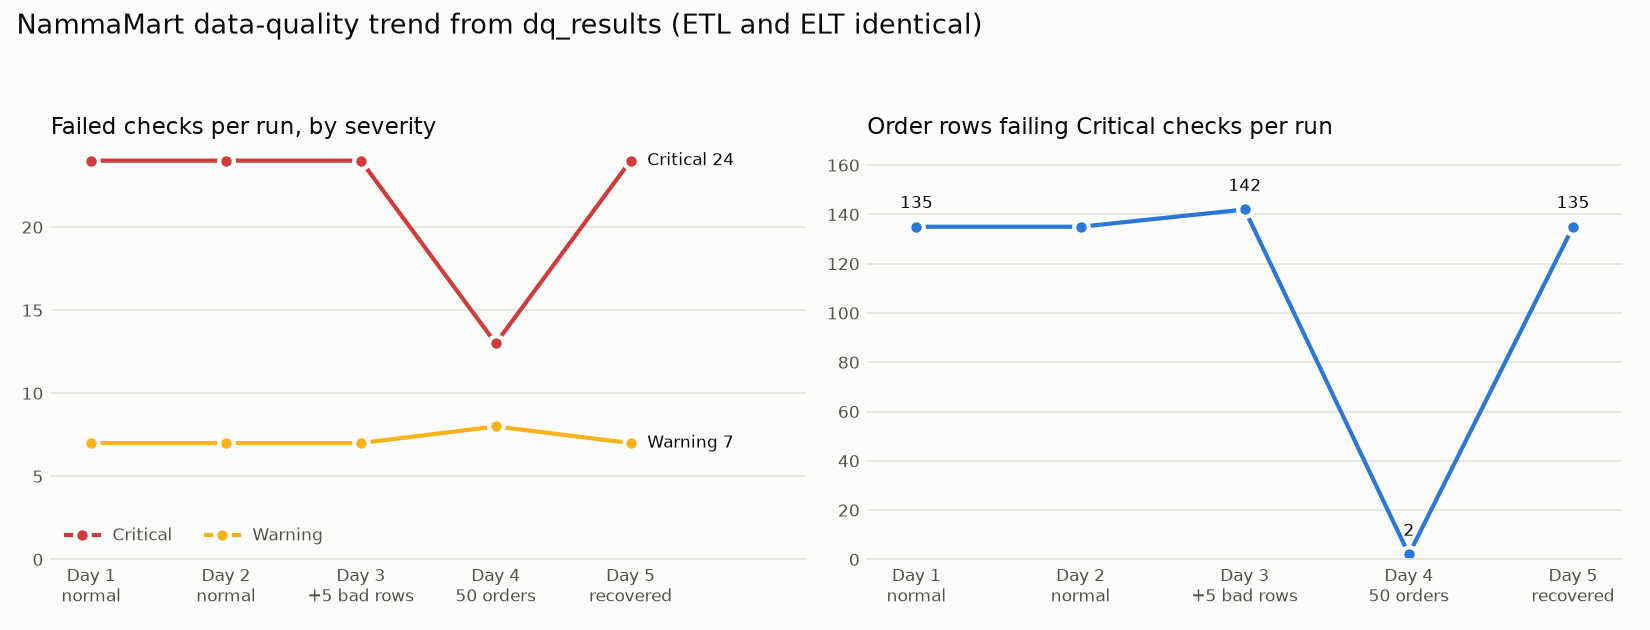

In [10]:
chart = plot_dq_trend(etl_trend, REPO_ROOT / 'assignment' / 'dq_trend.png',
                      'NammaMart data-quality trend from dq_results (ETL and ELT identical)', labels=labels)
print('Saved', chart.relative_to(REPO_ROOT))
from IPython.display import Image
Image(filename=str(chart))

In [11]:
# The same function charts the real Airflow history once scheduled runs accumulate.
live = load_dq_trend(REPO_ROOT / 'include' / 'warehouse_samy.duckdb', dag_id='nammamart_etl_samy')
print(f"Runs recorded in the Airflow ETL warehouse: {len(live)}")
live.tail(5)

Runs recorded in the Airflow ETL warehouse: 6


,run_id,checked_at,critical_failed_checks,warning_failed_checks,critical_failed_rows,critical_failed_order_rows,orders_checked,checks
1,manual__2026-10-22T12_56_50_531453_00_00,2026-10-22 14:56:59.241602,24,7,200.0,135.0,2562,37
2,manual__2026-10-22T13_01_17_001363_00_00,2026-10-22 15:01:25.922102,24,7,200.0,135.0,2562,37
3,manual__2026-10-22T13_04_03_755198_00_00,2026-10-22 15:04:09.136605,24,7,200.0,135.0,2562,37
4,manual__2026-10-22T13_16_35_631115_00_00,2026-10-22 15:16:53.346488,24,7,200.0,135.0,2562,37
5,manual__2026-10-22T13_47_07_240822_00_00,2026-10-22 15:47:12.431524,24,7,200.0,135.0,2562,38


In [12]:
shutil.rmtree(WORK)
print('Step 15 bonus features validated: Slack alert, store-capacity check, SCD2 history, dq trend chart.')

Step 15 bonus features validated: Slack alert, store-capacity check, SCD2 history, dq trend chart.
